author: ransell

# Bradley-Terry Analysis


**Note:** Ensure that any dataset paths are set at the top of this notebook before running all cells.

In [1]:
!pip install statsmodels numpy seaborn matplotlib

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached patsy-1.0.1-py2.py3-none-any.whl.metadata (3.3 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.4.8-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (6.2 kB)
  Using cached pillow-11.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.0 kB)
  Using cached pyparsing-3.2.3-py3-none-any.whl.metadata (5.0 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 45.7 MB/s  0:00:00 eta 0:00:01
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 65.7 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 63.1 MB/s  0:00:00
Using cached kiwisolver-1.4.8-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (1.5 MB)
Using cached patsy-1.0.1-py2.py3-none-any.whl (232 kB)
Using cached pillow-11.3.0-

**Bradley-Terry Rankings for X and YT pairs**

At this point -> the more positive the normalized ranking between -1 and 1, the more AI like the post. 

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

def run_bt_analysis(file_path, output_csv):
    data = pd.read_csv(file_path)
    data = data[data['post_winner'] != data['post_loser']].reset_index(drop=True)
    
    pairs = pd.DataFrame({'winner': data['post_winner'], 'loser': data['post_loser']})
    winners = pairs['winner'].dropna().astype(str).unique()
    losers  = pairs['loser'].dropna().astype(str).unique()
    teams = pd.Series(np.union1d(winners, losers))

    pairs['winner_code'] = pd.Categorical(pairs['winner'].astype(str), categories=teams).codes
    pairs['loser_code']  = pd.Categorical(pairs['loser'].astype(str), categories=teams).codes

    X = np.zeros((len(pairs), len(teams)))
    X[np.arange(len(pairs)), pairs['winner_code']] = 1
    X[np.arange(len(pairs)), pairs['loser_code']]  = -1
    y = np.ones(len(pairs))

    model = sm.GLM(y, X[:, 1:], family=sm.families.Binomial())
    results = model.fit()

    abilities = np.concatenate(([0], results.params))
    norm = -1 + 2 * (np.argsort(np.argsort(abilities)) / (len(abilities) - 1))

    rankings = []
    for i, post in enumerate(teams):
        if post in data['post_winner'].astype(str).values:
            text_id = data[data['post_winner'].astype(str) == post].iloc[0]['id_winner']
        else:
            text_id = data[data['post_loser'].astype(str) == post].iloc[0]['id_loser']
        rankings.append({'Text': post, 'Text_ID': int(text_id), 'Ability': abilities[i], 'Normalized Ability': norm[i]})
    
    pd.DataFrame(rankings).to_csv(output_csv, index=False)
    print(f"Saved: {output_csv}")

# Run for both platforms
run_bt_analysis("data/tt_data.csv",  "data/bt_tt_posts_rankings.csv")
run_bt_analysis("data/ts_data.csv", "data/bt_ts_posts_rankings.csv")


Saved: data/bt_tt_posts_rankings.csv
Saved: data/bt_ts_posts_rankings.csv


Merging in metadata from selected_posts

In [3]:
import pandas as pd
import numpy as np

def merge_bt_with_model_and_persona(
    bt_path,           
    posts_path,        # Path to model + human post metadata CSV
    post_text_col,     
    output_path,       
    label             
):
    print(f"\n--- Merging for {label} ---")

    # Load data
    bt_df = pd.read_csv(bt_path)
    posts_df = pd.read_csv(posts_path)

    # Normalize text
    bt_df['Text'] = bt_df['Text'].astype(str).str.strip()
    posts_df[post_text_col] = posts_df[post_text_col].astype(str).str.strip()

    # Separate AI and human posts
    ai_df = posts_df[posts_df['source'].str.lower() != 'human']
    human_df = posts_df[posts_df['source'].str.lower() == 'human']

    # Drop duplicate posts to prevent merge explosion
    ai_df = ai_df.drop_duplicates(subset=post_text_col, keep='first')
    human_df = human_df.drop_duplicates(subset=post_text_col, keep='first')

    # Merge AI metadata (source, persona) by post text
    merged = pd.merge(
        bt_df,
        ai_df[[post_text_col, 'source', 'persona']],
        left_on='Text',
        right_on=post_text_col,
        how='left'
    ).drop(columns=[post_text_col], errors='ignore')

    # Derive model column: if no AI source matched, it's human
    merged['model'] = merged['source'].apply(
        lambda x: str(x).strip().lower() if pd.notna(x) else 'human'
    )

    # Set persona to NaN for human posts
    merged['persona'] = merged.apply(
        lambda row: row['persona'] if row['model'] != 'human' else np.nan,
        axis=1
    )

    # Drop duplicates just in case
    merged = merged.drop_duplicates()

    # Save
    merged.to_csv(output_path, index=False)
    print(f"Saved to {output_path} ({len(merged)} records)")

# Run for both platforms with updated names ('x' → 'tt', 'yt' → 'ts')
merge_bt_with_model_and_persona(
    bt_path='data/bt_tt_posts_rankings.csv',
    posts_path='data/tt_posts_meta.csv',
    post_text_col='generated_post',
    output_path='data/bt_tt_posts_rankings_with_source_persona.csv',
    label='TT Platform'
)

merge_bt_with_model_and_persona(
    bt_path='data/bt_ts_posts_rankings.csv',
    posts_path='data/ts_posts_meta.csv',
    post_text_col='post',
    output_path='data/bt_ts_posts_rankings_with_source_persona.csv',
    label='TS Platform'
)



--- Merging for TT Platform ---
Saved to data/bt_tt_posts_rankings_with_source_persona.csv (600 records)

--- Merging for TS Platform ---
Saved to data/bt_ts_posts_rankings_with_source_persona.csv (593 records)


Checking Counts (debugging)

In [ ]:
import pandas as pd

def report_model_and_persona_counts(file_path, label):
    print(f"\n--- {label} ---")
    df = pd.read_csv(file_path)

    # Count model types
    model_counts = df['model'].value_counts()
    print("Model counts:")
    print(model_counts.to_string())

    # Count personas (including NaN)
    persona_counts = df['persona'].value_counts(dropna=False)
    print("\nPersona counts:")
    print(persona_counts.to_string())

    # check for persona assigned to human posts
    leaks = df[(df['model'] == 'human') & (df['persona'].notna())]
    if not leaks.empty:
        print(f"\nWarning: {len(leaks)} human-labeled posts have a non-null persona!?")
    else:
        print("\nNo persona leakage into human posts.")

# TT platform
report_model_and_persona_counts(
    file_path='data/bt_tt_posts_rankings_with_source_persona.csv',
    label='TT Platform'
)

# TS platform
report_model_and_persona_counts(
    file_path='data/bt_ts_posts_rankings_with_source_persona.csv',
    label='TS Platform'
)



--- TT Platform ---
Model counts:
model
human          179
llama3_2_3b     76
gpt_4o_mini     75
gpt_4           75
gpt_4o          75
llama_3_3       73
llama2_70b      47

Persona counts:
persona
NaN                               179
ProgressiveCommentator             87
LiberalCommentator                 86
ModerateCommentator                85
LibertarianPopulistCommentator     82
ConservativeCommentator            81

No persona leakage into human posts.

--- TS Platform ---
Model counts:
model
human          161
gpt_4           75
gpt_4o_mini     75
llama2_70b      73
gpt_4o          72
llama_3_3       71
llama3_2_3b     66

Persona counts:
persona
NaN                               161
libertarianpopulistcommentator     89
moderatecommentator                87
conservativecommentator            87
liberalcommentator                 87
progressivecommentator             82

No persona leakage into human posts.


**Inverting Normalized Ability, Positive = Humanlike; Negative = AI-like**

In [5]:
import pandas as pd

def invert_normalized_ability(input_path, output_path, label):
    print(f"\n--- Inverting Normalized Ability for {label} ---")
    df = pd.read_csv(input_path)

    if 'Normalized Ability' not in df.columns:
        raise ValueError("Column 'Normalized Ability' not found in input file.")

    # Invert the normalized ability score
    df['Normalized Ability'] = -df['Normalized Ability']

    # Save to a new CSV
    df.to_csv(output_path, index=False)
    print(f"Inverted scores saved to {output_path}")

# TT Platform
invert_normalized_ability(
    input_path='data/bt_tt_posts_rankings_with_source_persona.csv',
    output_path='data/bt_tt_posts_rankings_with_source_persona_inverted.csv',
    label='TT Platform'
)

# TS Platform
invert_normalized_ability(
    input_path='data/bt_ts_posts_rankings_with_source_persona.csv',
    output_path='data/bt_ts_posts_rankings_with_source_persona_inverted.csv',
    label='TS Platform'
)



--- Inverting Normalized Ability for TT Platform ---
Inverted scores saved to data/bt_tt_posts_rankings_with_source_persona_inverted.csv

--- Inverting Normalized Ability for TS Platform ---
Inverted scores saved to data/bt_ts_posts_rankings_with_source_persona_inverted.csv


## Various Vizualisation Experiments

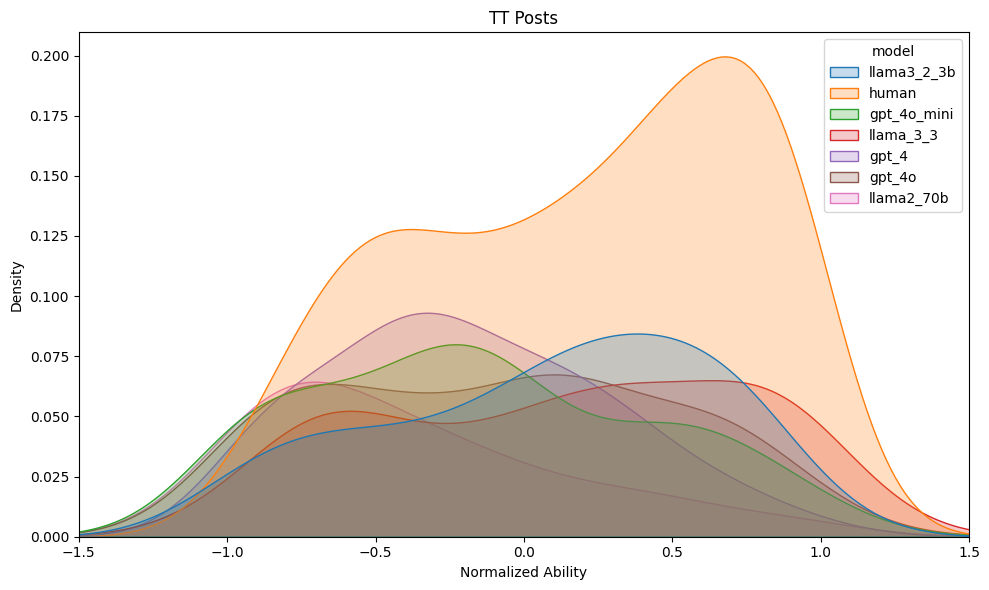


--- TT Stats ---
             count      mean       std       min       max    median      mode
model                                                                         
gpt_4           75 -0.195326  0.475711 -0.969950  0.993322 -0.268781 -0.969950
gpt_4o          75 -0.086032  0.574980 -0.996661  0.976628 -0.031720 -0.996661
gpt_4o_mini     75 -0.147646  0.561929 -0.993322  0.949917 -0.185309 -0.993322
human          179  0.193348  0.556799 -0.973289  0.989983  0.268781 -0.973289
llama2_70b      47 -0.378397  0.514084 -1.000000  0.909850 -0.525876 -1.000000
llama3_2_3b     76  0.077805  0.546989 -0.989983  0.956594  0.178631 -0.989983
llama_3_3       73  0.129279  0.602728 -0.966611  1.000000  0.225376 -0.966611


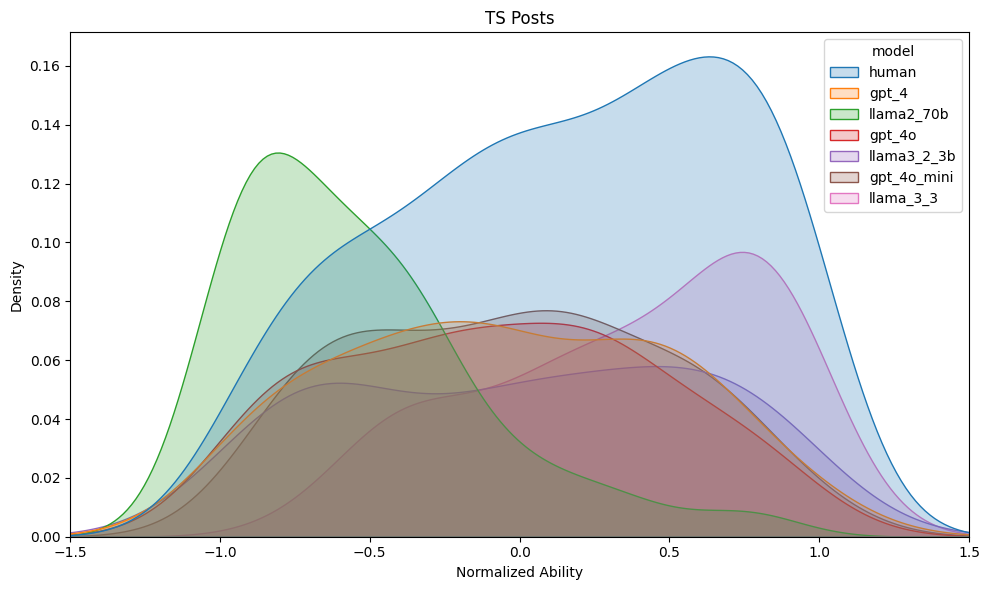


--- TS Stats ---
             count      mean       std       min       max    median      mode
model                                                                         
gpt_4           75 -0.047973  0.542746 -0.976351  0.993243 -0.060811 -0.976351
gpt_4o          72 -0.079486  0.528843 -0.962838  0.915541 -0.104730 -0.962838
gpt_4o_mini     75 -0.025180  0.513893 -0.932432  1.000000 -0.020270 -0.932432
human          161  0.150705  0.564852 -0.986486  0.979730  0.189189 -0.986486
llama2_70b      73 -0.542669  0.411130 -1.000000  0.770270 -0.631757 -1.000000
llama3_2_3b     66  0.017506  0.593124 -0.993243  0.996622  0.047297 -0.993243
llama_3_3       71  0.357823  0.479738 -0.712838  0.989865  0.415541 -0.712838


In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Utility function to plot KDE and print stats
def plot_and_describe(df, label):
    df['model'] = df['model'].fillna("human")

    # KDE plot
    plt.figure(figsize=(10, 6))
    sns.kdeplot(data=df, x="Normalized Ability", hue="model", fill=True)
    plt.title(f"{label} Posts")
    plt.xlabel("Normalized Ability")
    plt.ylabel("Density")
    plt.xlim(-1.5, 1.5)
    plt.tight_layout()
    plt.show()

    # Summary stats
    grouped = df.groupby('model')['Normalized Ability']
    stats_df = grouped.agg(['count', 'mean', 'std', 'min', 'max'])
    stats_df['median'] = grouped.median()
    stats_df['mode'] = grouped.apply(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)

    print(f"\n--- {label} Stats ---")
    print(stats_df)

# Load inverted TT data
df_tt = pd.read_csv("data/bt_tt_posts_rankings_with_source_persona_inverted.csv")
plot_and_describe(df_tt, label="TT")

# Load inverted TS data
df_ts = pd.read_csv("data/bt_ts_posts_rankings_with_source_persona_inverted.csv")
plot_and_describe(df_ts, label="TS")


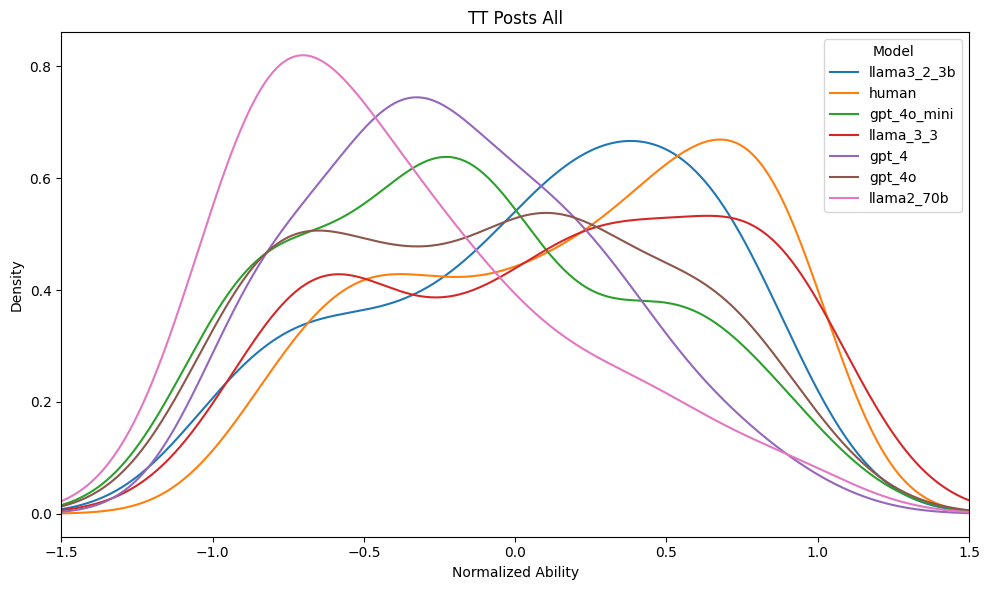

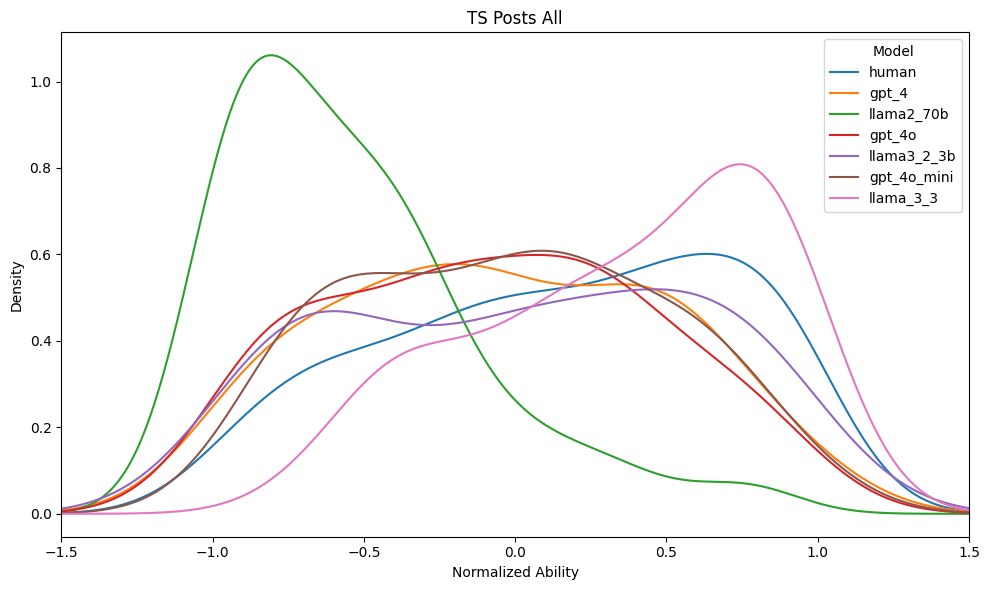

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_kde_platform(file_path, title):
    # Load and clean
    df = pd.read_csv(file_path)
    df['model'] = df['model'].fillna("human")
    
    # Set up figure
    plt.figure(figsize=(10, 6))
    ax = plt.gca()
    
    # Plot a KDE for each model
    for model in df['model'].unique():
        series = df.loc[df['model'] == model, 'Normalized Ability'].dropna()
        if not series.empty:
            series.plot.kde(ax=ax, label=model)
    
    # Labels and limits
    plt.title(f"{title} Posts All")
    plt.xlabel("Normalized Ability")
    plt.ylabel("Density")
    plt.xlim(-1.5, 1.5)
    plt.legend(title="Model")
    plt.tight_layout()
    plt.show()

# TT platform
plot_kde_platform(
    file_path= "data/bt_tt_posts_rankings_with_source_persona_inverted.csv",
    title='TT'
)

# TS platform
plot_kde_platform(
    file_path="data/bt_ts_posts_rankings_with_source_persona_inverted.csv",
    title='TS'
)


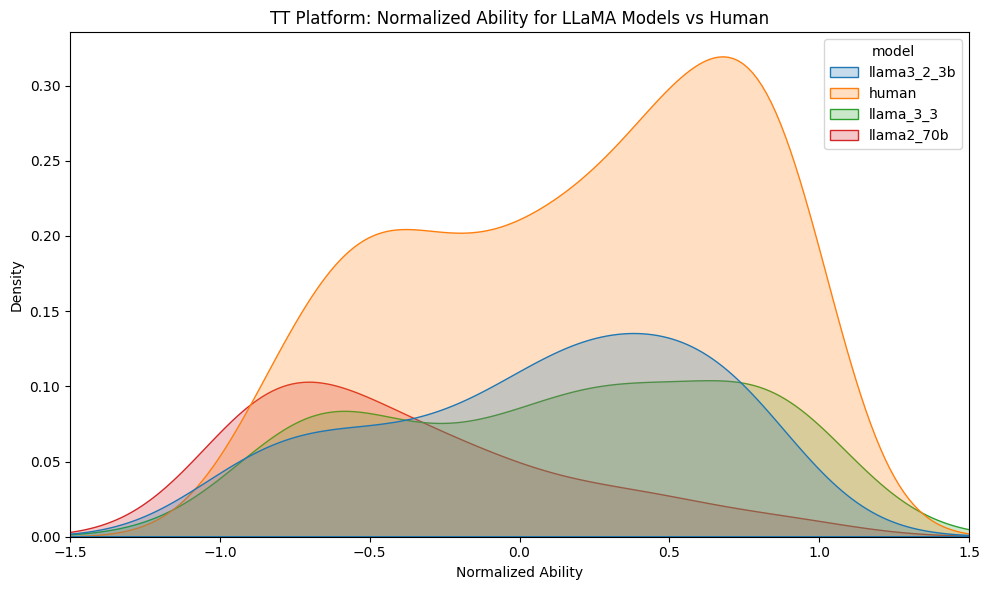

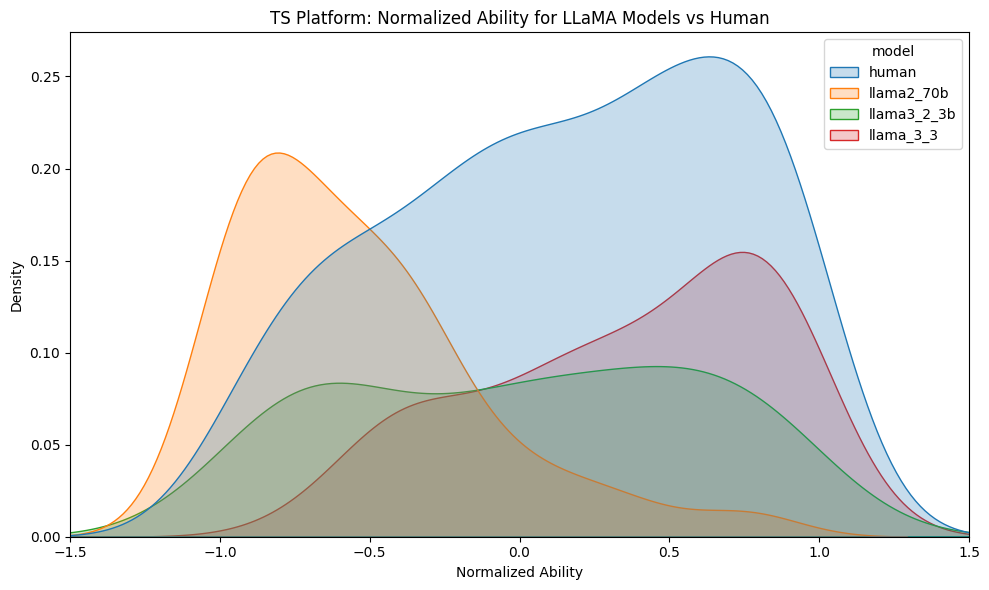

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_llama_vs_human(df, label):
    df['model'] = df['model'].fillna("human")

    # Filter for LLaMA models or human
    df_filtered = df[
        df['model'].str.contains("llama", case=False, na=False) | 
        (df['model'] == "human")
    ]

    # Plot
    plt.figure(figsize=(10, 6))
    sns.kdeplot(data=df_filtered, x="Normalized Ability", hue="model", fill=True)
    plt.title(f"{label}: Normalized Ability for LLaMA Models vs Human")
    plt.xlabel("Normalized Ability")
    plt.ylabel("Density")
    plt.xlim(-1.5, 1.5)
    plt.tight_layout()
    plt.show()

# TT Platform
df_tt = pd.read_csv("data/bt_tt_posts_rankings_with_source_persona_inverted.csv")
plot_llama_vs_human(df_tt, label="TT Platform")

# TS Platform
df_ts = pd.read_csv("data/bt_ts_posts_rankings_with_source_persona_inverted.csv")
plot_llama_vs_human(df_ts, label="TS Platform")


/tmp/ipykernel_3829771/123680184.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(


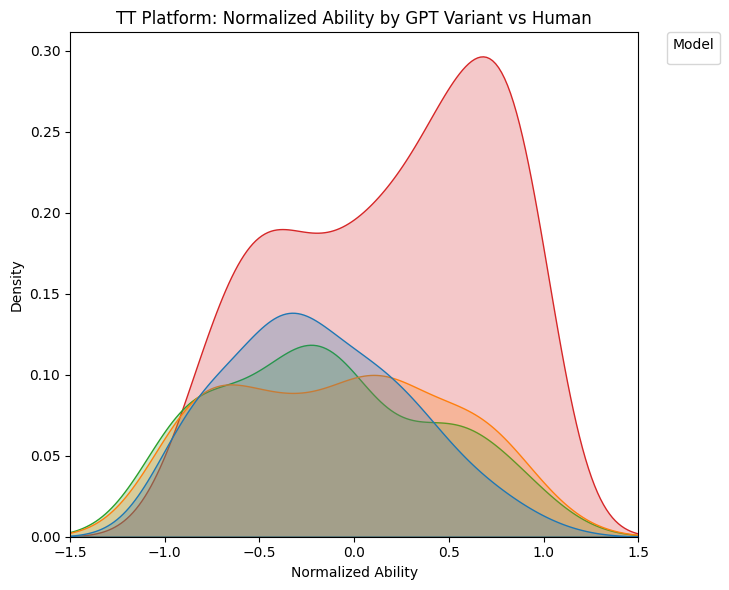

/tmp/ipykernel_3829771/123680184.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(


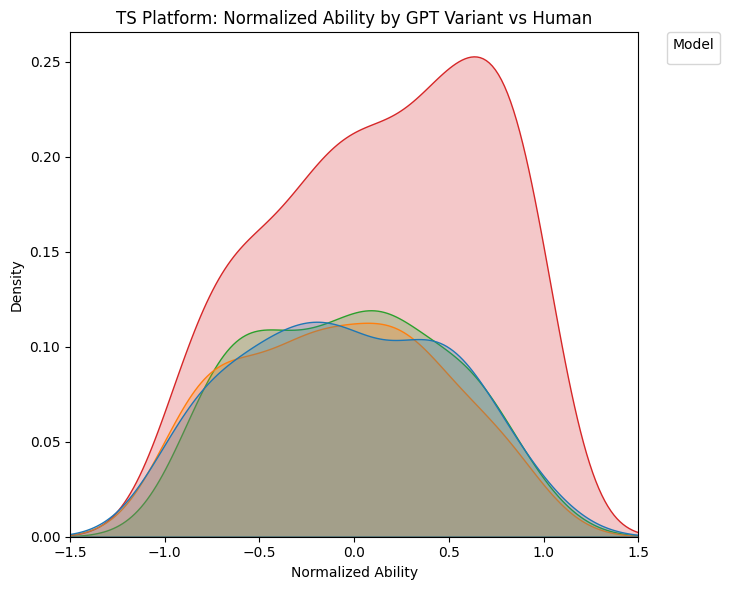

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_each_gpt_variant(df, label):
    df['model'] = df['model'].fillna("human").astype(str).str.strip()

    # Create display labels
    def label_model(x):
        if x.lower() == 'human':
            return 'Human'
        elif 'gpt' in x.lower():
            return x.replace('_', '-').upper()
        else:
            return None

    df['model_label'] = df['model'].apply(label_model)
    df_filtered = df[df['model_label'].notna()]

    # Determine legend order (alphabetical here, but you can hard-code a list)
    hue_order = sorted(df_filtered['model_label'].unique())

    plt.figure(figsize=(10, 6))
    ax = sns.kdeplot(
        data=df_filtered,
        x="Normalized Ability",
        hue="model_label",
        hue_order=hue_order,
        fill=True
    )
    plt.title(f"{label}: Normalized Ability by GPT Variant vs Human")
    plt.xlabel("Normalized Ability")
    plt.ylabel("Density")
    plt.xlim(-1.5, 1.5)

    # Pull the legend out to the right
    ax.legend(
        title="Model",
        bbox_to_anchor=(1.05, 1),
        loc='upper left',
        borderaxespad=0.
    )

    plt.tight_layout(rect=[0, 0, 0.75, 1])  # leave room on right for legend
    plt.show()

# TT Platform
df_tt = pd.read_csv("data/bt_tt_posts_rankings_with_source_persona_inverted.csv")
plot_each_gpt_variant(df_tt, "TT Platform")

# TS Platform
df_ts = pd.read_csv("data/bt_ts_posts_rankings_with_source_persona_inverted.csv")
plot_each_gpt_variant(df_ts, "TS Platform")


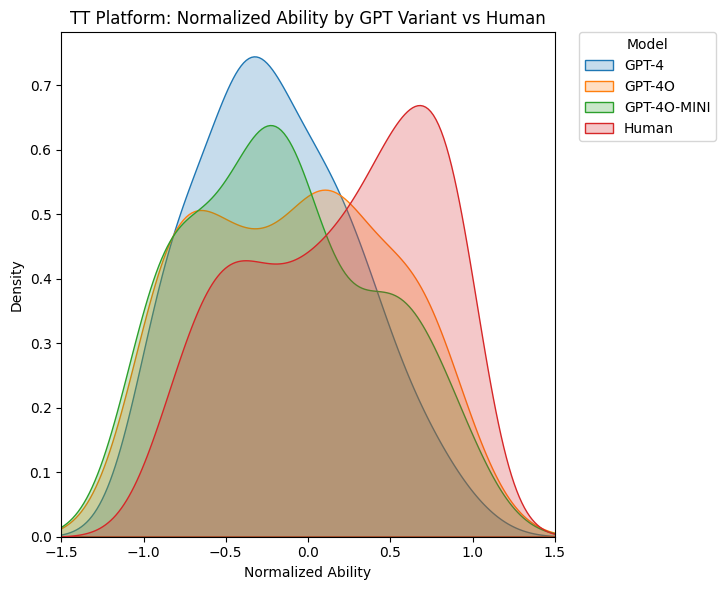

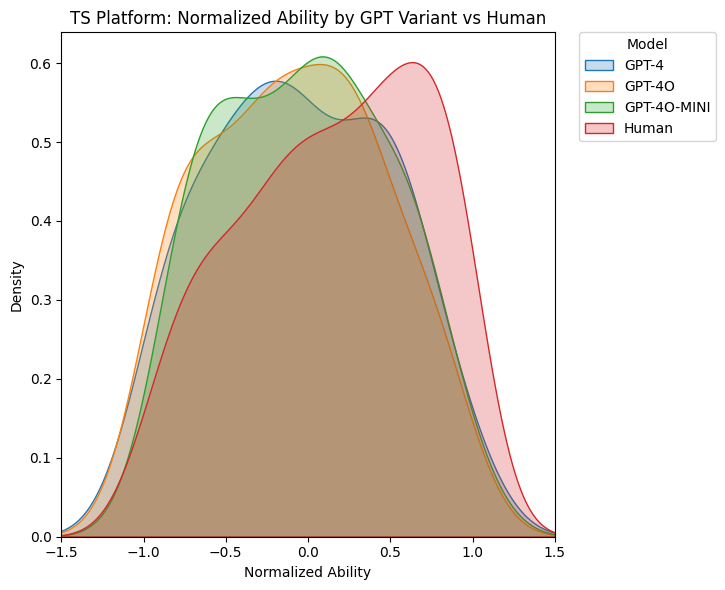

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_each_gpt_variant(df, label):
    # Fill missing as “human” and strip whitespace
    df['model'] = df['model'].fillna("human").astype(str).str.strip()

    # Build a “pretty” label for each model
    def label_model(x):
        if x.lower() == 'human':
            return 'Human'
        elif 'gpt' in x.lower():
            return x.replace('_', '-').upper()
        else:
            return None

    df['model_label'] = df['model'].apply(label_model)
    df_filtered = df[df['model_label'].notna()]

    # Decide in what order you want the curves/legend
    hue_order = sorted(df_filtered['model_label'].unique())

    fig, ax = plt.subplots(figsize=(10, 6))

    # Plot each variant separately so legend entries are guaranteed
    for variant in hue_order:
        subset = df_filtered[df_filtered['model_label'] == variant]
        sns.kdeplot(
            data=subset,
            x="Normalized Ability",
            fill=True,
            ax=ax,
            label=variant,    # this makes the legend entry
            common_norm=False  # normalize each curve independently
        )

    # Decorations
    ax.set_title(f"{label}: Normalized Ability by GPT Variant vs Human")
    ax.set_xlabel("Normalized Ability")
    ax.set_ylabel("Density")
    ax.set_xlim(-1.5, 1.5)

    # Move the legend outside on the right
    ax.legend(
        title="Model",
        bbox_to_anchor=(1.05, 1),
        loc='upper left',
        borderaxespad=0.
    )

    plt.tight_layout(rect=[0, 0, 0.75, 1])
    plt.show()


# TT Platform
df_tt = pd.read_csv("data/bt_tt_posts_rankings_with_source_persona_inverted.csv")
plot_each_gpt_variant(df_tt, "TT Platform")

# TS Platform
df_ts = pd.read_csv("data/bt_ts_posts_rankings_with_source_persona_inverted.csv")
plot_each_gpt_variant(df_ts, "TS Platform")
